# Principios básicos de valoración de bonos

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sympy import Symbol
import scipy.optimize as optimize
from scipy.optimize import linprog
from scipy.optimize import minimize
from scipy.interpolate import CubicSpline, interp1d, make_interp_spline, UnivariateSpline
from scipy.optimize import newton, fsolve
from matplotlib.ticker import FuncFormatter


# Estructura temporal de los tipos de interés ETTI

La estructura temporal de los tipos de interés es una función que describe la relación entre los tipos de interés y los diferentes plazos, es decir, los instantes de tiempo o los vencimientos.

La aproximación más simple es mostrar __las rentabilidades a vencimiento__ que ofrecen un conjunto de títulos con distintos vencimientos y niveles de riesgo y liquidez similares. La curva de rendimiento al vencimiento contiene algunas imprecisiones. La principal limitacón de la medida del rendimiento al vencimiento, es la hipótesis de tasa de reinversión constante del cupón durante la vida del bono al a la tasa de rentabildad estimada. Es lo que se conoce como riesgo de reinversión. Solo los tenedores de __bonos cupón cero__ evitan el riesgo de reinversión, ya que no se paga ningún cupón durante la vida de un bono cupón cero.

La __curva de rendimiento al vencimiento__ no distingue entre los diferentes patrones de pago que pueden derivarse de bonos con diferentes cupones, es decir, el hecho de que los bonos con cupones bajos pagan una mayor parte de sus flujos de efectivo en una fecha posterior que los bonos con cupones altos del mismo vencimiento.

La __curva de rendimiento de los cupones__ es un gráfico que representa el rendimiento al vencimiento en función del plazo hasta el vencimiento de un grupo de bonos con el mismo cupón. Si construimos dicha curva, podemos observar que, en general, los bonos con cupones altos se negocian con descuento (tienen rendimientos más altos) en comparación con los bonos con cupones bajos, debido al riesgo de reinversión y por motivos fiscales.

La __curva de rendimiento nominal__ representa el rendimiento al vencimiento en función del plazo hasta el vencimiento de los bonos actuales que cotizan a la par.

Supongamos que disponemnos en el mercado de 5 emisiones de bonos cupón cero.

In [5]:
# Cargar archivo Excel
df = pd.read_excel('Cupon_Zero.xlsx', sheet_name='Hoja1')

# Mostrar las primeras filas
print(df.head())

   Vencimiento  Valor_Nominal   Precio
0            1            100   97.561
1            2            105   98.018
2            3            110   97.790
3            4            120  101.013
4            5            125   99.115


Determina la rentabilidad de los bonos cupón cero, tambien denominada __tipo spot__ de la estructura temporal de los tipos de interés.
$$S_t=\left(\frac{VN}{P}\right)^{1/t}-1$$

In [6]:
# Calcular el tipo spot y añadirlo como nueva columna
df['spot'] = (df['Valor_Nominal'] / df['Precio']) ** (1 / df['Vencimiento']) - 1
print(df.head())

   Vencimiento  Valor_Nominal   Precio      spot
0            1            100   97.561  0.025000
1            2            105   98.018  0.035003
2            3            110   97.790  0.039999
3            4            120  101.013  0.044001
4            5            125   99.115  0.047500


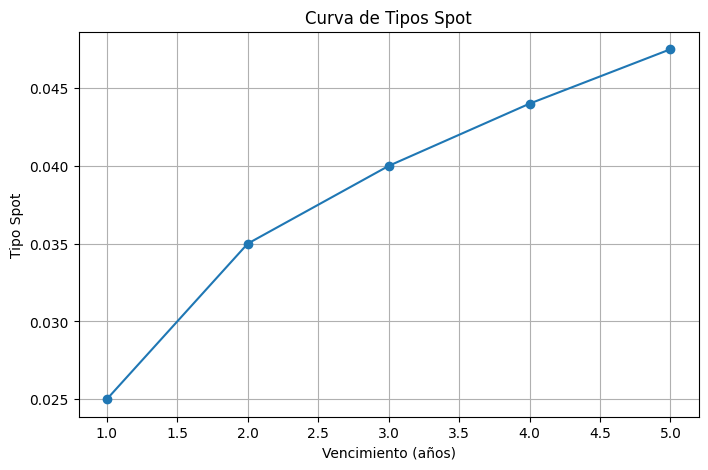

In [7]:
# Crear el gráfico de la curva de tipos spot
plt.figure(figsize=(8, 5))
plt.plot(df['Vencimiento'], df['spot'], marker='o')
plt.title('Curva de Tipos Spot')
plt.xlabel('Vencimiento (años)')
plt.ylabel('Tipo Spot')
plt.grid(True)
plt.show()

Los tipos de interés spot son esenciales para determinar el precio de los bonos, es lo que utilizamos para estimar el precio teórico de un bono.

A efectos de valor relativo, los operadores y gestores de carteras suelen comparar el precio real de mercado de un bono con su precio teórico, utilizando la curva de cupón cero para cada flujo de efectivo, y determinan si el bono es «barato» o «caro». Cuando existe cierta desviación entre el precio teórico de un bono y el precio real, la decisión de comprar o vender puede basarse en factores subjetivos, ya que a menudo no existe ningún instrumento cupón cero con el que realizar una operación de arbitraje. Cuando existe un mercado de bonos cupones cero los mercados están arbitrados y las diferencias entre los precios teóricos y reales se reducen considerablemente.

En un mercado en el que no se negocian instrumentos de cupón cero, los tipos spot son teóricos y no están representados por los precios reales de mercado. Por lo tanto, los operadores suelen analizar los bonos en términos de valor relativo entre sí y las rentabilodades a vencimiento, en lugar de compararlos con su precio teórico basado en el cupón cero.

A pesar de ello, es importante que  la curva de rendimiento de cupón cero se construya con la mayor precisión posible. Esto se debe a que la curva se utiliza en la valoración de una amplia gama de instrumentos, sino también de otros productos de tipo de interés, como los swaps o los derivados de tipo de interés.

Utilizando la anterior ETTI estima el valor teórico de un bono del estado de valor nominal 1000 € con vencimiento a 5 años y cupón anual del 3.25%.

$$P=\sum_{t=1}^5\frac{C}{(1+S_t)^t}+\frac{1000}{(1+S_5)^5}$$
La ecuación puede plantearse matricialmente.
$$d=\left[\frac{1}{(1+S_1)^1},\frac{1}{(1+S_2)^2},...,\frac{1}{(1+S_t)^t},...,\frac{1}{(1+S_5)^5}\right]$$
$$P=[C_1,C_2,C_3,C_4,C_5]\left[\begin{array}{crl}
d_1\\
d_2\\
d_3 \\
d_4 \\
d_5
\end{array}\right]$$

In [8]:
# Datos del bono
valor_nominal = 1000
cupon_anual = 0.0325
vencimiento = 5

# Crear vector de flujos de caja
# Cupones anuales durante los primeros 4 años, y cupón + nominal en el último año
flujos = [valor_nominal * cupon_anual] * (vencimiento - 1) + [valor_nominal * cupon_anual + valor_nominal]
flujos

[32.5, 32.5, 32.5, 32.5, 1032.5]

In [9]:
#Estimamos las tasas de descuento
df['d'] = 1 / (1 + df['spot']) ** df['Vencimiento']
df

,Vencimiento,Valor_Nominal,Precio,spot,d
0,1,100,97.561,0.025000,0.975610
1,2,105,98.018,0.035003,0.933505
2,3,110,97.790,0.039999,0.889000
3,4,120,101.013,0.044001,0.841775
4,5,125,99.115,0.047500,0.792920


In [11]:
# Extraer el vector de flujos y el vector de tasas de descuento
flujos_vector = np.array(flujos)
descuentos_vector = df['d']

# Realizar la operación matricial
precio_bono = flujos_vector @ descuentos_vector

print("El precio del bono es :",round(precio_bono,2))

El precio del bono es : 936.99


Si trabajamos con tiempo continuo tendremos que estimar unas tasas de descuento diferentes:

$$d=\left[e^{-S_1\times 1},e^{-S_2\times 2},...,e^{-S_t\times t},...,e^{-S_5\times 5}\right]$$


In [13]:
#Estimamos las tasas de descuento en tiempo continuo
df['dc'] = np.exp(-df['spot'] * df['Vencimiento'])
df

,Vencimiento,Valor_Nominal,Precio,spot,d,dc
0,1,100,97.561,0.025000,0.975610,0.975310
1,2,105,98.018,0.035003,0.933505,0.932388
2,3,110,97.790,0.039999,0.889000,0.886924
3,4,120,101.013,0.044001,0.841775,0.838614
4,5,125,99.115,0.047500,0.792920,0.788596


In [14]:
# Realizar la operación matricial
descuentos_vector_c = df['dc']
precio_bono_c = flujos_vector @ descuentos_vector_c

print("El precio del bono es :",round(precio_bono_c,2))

El precio del bono es : 932.31


## Método Bootstrap para estimar la ETTI

La realidad es mucho más compleja y no disponemos de bonos cupones cero para cada uno de los vencimientos. Por ello utilizaremos el método bootstrap para estimar la ETTI a partir de las distintas emisiones de renta fija.

Veamos un ejemplo. Supongamos que disponemos de cuatro bonos con vencimiento a 1,2,3 y 4 años. Ofrecen un cupón de 5% y su valor nominal es de 1000€. Los precios de cada uno de ellos se detallan a continuación

In [16]:
par= 1000
coup=0.05
bonds_df1 =pd.DataFrame()
bonds_df1['Maturity'] = [1,2,3,4]
bonds_df1['Price'] = [1000, 995.49, 989.08, 982.63]
bonds_df1

,Maturity,Price
0,1,1000.00
1,2,995.49
2,3,989.08
3,4,982.63


Podemos tratar el primer bono como un bono cupón cero y estimar el tipo spot a un año.
$$1,000=\frac{50+1000}{(1+S_1)^1}\rightarrow S_1=5.00%$$

In [22]:
spot= []
S1=((par*(1+coup))/bonds_df1['Price'][0]-1)
FCD1=(par*(1+coup))/(1+S1)
spot.append(S1)
print(round(S1,4), round(FCD1,2))

0.05 1000.0


Podemos despejar $S_2$ del bono con vencimiento a dos años.
$$995.49=\frac{50}{(1+S_1)^1}+\frac{50+1000}{(1+S_2)^2}$$

In [23]:
S2=(((par*(1+coup))/(bonds_df1['Price'][1]-(par*coup/(1+S1))))**(1/2)-1)
FCD2=(par*coup)/(1+S1)+(par*(1+coup))/((1+S2)**2)
spot.append(S2)
print(round(S2,4), round(FCD2,2))

0.0525 995.49


In [24]:
S3=(((par*(1+coup))/(bonds_df1['Price'][2]-(par*coup/(1+S1))-(par*coup/(1+S2)**(2))))**(1/3)-1)
FCD3=(par*coup)/(1+S1)+(par*coup)/((1+S2)**2)+(par*(1+coup))/((1+S3)**3)
spot.append(S3)
print(round(S3,4), round(FCD3,2))

0.0542 989.08


In [26]:
S4=(((par*(1+coup))/(bonds_df1['Price'][3]-(par*coup/(1+S1))-(par*coup/(1+S2)**2)-(par*coup/(1+S3)**3))))**(1/4)-1
FCD4=(par*coup)/(1+S1)+(par*coup)/((1+S2)**2)+(par*coup)/((1+S3)**3)+(par*(1+coup))/((1+S4)**4)
spot.append(S4)
print(round(S4,4), round(FCD4,2))

0.0551 982.63


In [ ]:
bonds_df1['Spot']=np.array(spot)
bonds_df1

,Maturity,Price,Spot
0,1,1000.00,0.050000
1,2,995.49,0.052495
2,3,989.08,0.054164
3,4,982.63,0.055120


`np.full(shape, fill_value)` crea un array de NumPy lleno con un mismo valor constante.
- shape: tamaño del array que quieres crear.
- fill_value: valor con el que se rellenan todos los elementos.


In [ ]:
n=len(bonds_df1['Maturity'])
par= 1000
coup=0.05
S_ytm=[]
# Tratamos al primer bono comos si fuese un bono cupón cero
s1=(par*(1+coup)/bonds_df1.loc[0, 'Price'])**(1/bonds_df1.loc[0, 'Maturity'])-1
S_ytm=[s1]
for i in range(1, n):
    f=np.full(int(bonds_df1.loc[i,'Maturity'])-1, par*coup)#flujos de caja
    d=((1+np.array(S_ytm)) ** (-bonds_df1.loc[:(i-1),'Maturity']))# tasas de descuento
    pv_cf = f@d
    S_ytm.append((par*(1+coup)/(bonds_df1.loc[i,'Price'] - pv_cf)) **(1/ bonds_df1.loc[i,'Maturity'])-1)

S_ytm = np.array(S_ytm)
print("Implied Spot Rates (c.c.) = ",S_ytm)

Implied Spot Rates (c.c.) =  [0.05       0.052495   0.05416369 0.05511998]


Determina el precio de un bono de valor nominal 1000 €, con vencimiento a cuatro años, cupón del 5% anual.  

Alternativa de trabajar con listas.
`[coupon] * (T - 1)`

Crea una lista con los cupones periódicos (todos iguales) antes del vencimiento.

Como T = 4, tenemos T - 1 = 3, así que:

Le añadimos el último pago

`[coupon + par]`

Para poder operar con matrices tendremos que convertir la lista en matriz

In [ ]:
T=4
par=1000
coup=0.05
coupon = coup*par
flujos_2 = [coupon] * (T - 1) + [coupon +par]
flujos_vector_2 = np.array(flujos_2)
bonds_df1['d'] = 1 / (1 + bonds_df1['Spot']) ** bonds_df1['Maturity']
descuentos_vector_2 = bonds_df1['d'].iloc[0:4]

precio_bono_2 = flujos_vector_2 @ descuentos_vector_2

precio_bono_2.item()

982.6299999999999

__Ejemplo 2__

Vamos a trabajar con tiempo continuo y los cupones se pagan semestralmente
$$ P=FC \times e^{-rt}$$
$$r=ln\left(\frac{FC}{P}\right)\times \frac{1}{t}$$

In [ ]:
# Vectores proporcionados
maturity = np.array([0.5, 1.0, 1.5, 2.0])
coupon = np.array([0, 0, 4, 5])
price = np.array([99, 97.80, 102.50, 105.00])
face = np.full(4, 100)
freq = 2

# Crear el DataFrame
df_bonos = pd.DataFrame({
    'Maturity': maturity,
    'Coupon': coupon,
    'Price': price
})
df_bonos

,Maturity,Coupon,Price
0,0.5,0,99.0
1,1.0,0,97.8
2,1.5,4,102.5
3,2.0,5,105.0


In [ ]:
S_ytm=[]
f = df_bonos['Maturity'].min()# frecuencia mínima
# Los dos primeros son bonos cupón cero
s1=np.log(100/df_bonos.loc[0, 'Price'])/df_bonos.loc[0, 'Maturity']
s2=np.log(100/df_bonos.loc[1, 'Price'])/df_bonos.loc[1, 'Maturity']
# Guardo los dos primeros spot
S_ytm=[s1,s2]
S_ytm

[np.float64(0.020100671707003012), np.float64(0.022245608947319737)]

Estimemos las tasas de descuento semestrales en tiempo continuo.
Empezamos con S_3

\begin{align}
103.5 &=4 e^{-0.5S_1}+4 e^{-S_2}+ e^{-1.5S_3} \\
1.5·S_3&=log\left(\frac{(100+4)}{103.5- 4 e^{-0.5S_1}-4 e^{-S_2}}\right) \\
S_3&=log\left(\frac{(100+4)}{103.5- 4 e^{-0.5S_1}-4 e^{-S_2}}\right)·\frac{1}{1.5}
\end{align}
Si deseamos estimar $S_4$
\begin{align}
105 &=4 e^{-0.5S_1}+4 e^{-S_2}+ 4 e^{-1.5S_3}+(100+4) e^{-2S_4} \\
2·S_4&=log\left(\frac{(100+4)}{103.5- 4 e^{-0.5S_1}-4 e^{-S_2}-4 e^{-1.5S_3}}\right) \\
S_4&=log\left(\frac{(100+4)}{103.5- 4 e^{-0.5S_1}-4 e^{-S_2}- 4 e^{-1.5S_3}}\right)·\frac{1}{2}
\end{align}

In [ ]:
n=len(df_bonos['Maturity'])
freq = 1/df_bonos['Maturity'].min()# frecuencia mínima
for i in range(2, n):
    f=np.full(int(df_bonos.loc[i, 'Maturity'] * freq) - 1,
                df_bonos.loc[i, 'Coupon'] / freq)
    dc=np.exp(-np.array(S_ytm) * df_bonos.loc[:(i-1), 'Maturity'])
    pv_cf=f@dc

    S_ytm.append(
        np.log((100 + df_bonos.loc[i, 'Coupon'] / freq)
               / (df_bonos.loc[i, 'Price'] - pv_cf))
        / df_bonos.loc[i, 'Maturity']
    )

S_ytm = np.array(S_ytm)
print("Implied Spot Rates (c.c.) = ",S_ytm)

Implied Spot Rates (c.c.) =  [0.02010067 0.02224561 0.02284449 0.02416379]


## Tipos de interés forward
El tipo de interés a plazo o __forward__ es la tasa de un préstamo a plazo. Hoy se determina el tipo de interés al que va a prestar el dinero en algún momento en el futuro y que se devolverá en algún momento posterior.

Al evidencia empírica sugiere que el tipo de interés forward no es un buen predictor de los tipos de interés futuros, frecuentemente los sobrevaloran. La pregunta que se plenta es ¿por qué se les da tanta importancia?

Los tipos de interés forward se utilizan fundamentalmente para diseñar estrategias de cobertura. Nos permite determinar cual debe ser tipo de interés de un préstamo a plazo, este contrato eliminaría la incertidumbre o ello a veces se les denominan tipos de interés de cobertura.

Los tipos de interés forward tambien representan la visión del mercados sobre la evolución futura de los tipos de interés.

![image.png](attachment:9a2fd77f-fae1-441a-8431-723c77b26a92.png)

$$(1+S_2)^2=(1+S_1)(1+F_{1,2})$$
$$F_{1,2}=\frac{(1+S_2)^2}{(1+S_1)}-1$$


In [ ]:
F_1_2=float(bonds_df1['Spot'][2-1])**2/float(bonds_df1['Spot'][1-1])
print(round(F_1_2,3))

0.055


Utilizando la ETTI determina el valor de un bono de valor nominal 1000 y cupón del 4% anual con vencimiento en cuatro año

In [ ]:
bonds_df1

,Maturity,Price,Spot,d
0,1,1000.00,0.050000,0.952381
1,2,995.49,0.052495,0.902734
2,3,989.08,0.054164,0.853642
3,4,982.63,0.055120,0.806850


In [ ]:
VN=1000
cupon=0.04
T=4
c=VN*cupon
f = [c] * (T - 1) + [c +VN]
f_a = np.array(f)
d=bonds_df1['d'][0:4]
p=f@d
print(round(p,3))

947.474


Determina la rentabilidad que obtendrías si vendes el bono transcurrido dos años y los tipos de interés han bajado de manera paralela en 0.5% (50 puntos básicos)

In [ ]:
bonds_df1['Spot_p']=bonds_df1['Spot']-0.005
bonds_df1

,Maturity,Price,Spot,d,Spot_p
0,1,1000.00,0.050000,0.952381,0.045000
1,2,995.49,0.052495,0.902734,0.047495
2,3,989.08,0.054164,0.853642,0.049164
3,4,982.63,0.055120,0.806850,0.050120


In [ ]:
# Nuevos tipos forward
F_2_3=((1+bonds_df1['Spot_p'][2])**3/(1+bonds_df1['Spot_p'][1])**2)-1
F_2_4=((1+bonds_df1['Spot_p'][3])**4/(1+bonds_df1['Spot_p'][1])**2)**(1/2)-1

In [ ]:
# Precio del bono transcurrido dos años
P_2=c/(1+F_2_3)+(VN+c)/(1+F_2_4)**2
print(round(P_2,2))

976.39


In [ ]:
dt = [(i+1) for i in range(int(2))]
ytm_func = lambda y: \
       sum([c/(1+y)**(t) for t in dt]) + \
       P_2/(1+y)**2 - p
TIR=(1+optimize.newton(ytm_func, 0.05))-1
print(dt)
print(f"La rentabilidad obtenida:{round(TIR,3)}")

[1, 2]
La rentabilidad obtenida:0.057


In [ ]:
def forward(i,j):
    S_i=float(bonds_df1['Spot'][i-1])
    S_j=float(bonds_df1['Spot'][j-1])
    f=((((1+S_j)**j)/((1+S_i)**i))**(1/(j-i))-1)
    return f

In [ ]:
forward(1,2)

0.0549959332418668

# Una aproximación matricial a la ETTI

Tenemos un conjunto de bonos con distintos vencimientos y queremos aplicar _bootstraping_ para estimar la ETTI. Para ello utilizaremos la siguiente aproximación matricial.
Construimos una matriz que recoja los flujos de caja generados por cada uno de los bonos que multiplicado por las tasas de descuentos implícitas en la ETTI nos permitirá determinar el precio de los bonos.

$$\left[\begin{array}{crl}
FC_{11} & 0 & 0 &\ldots& 0 \\
FC_{21} & FC_{22}& 0 &\ldots& 0\\
\vdots & \vdots & \vdots & \ldots&\vdots \\
FC_{N1} & FC_{N2} &FC_{N3}&\ldots&FC_{NN}
\end{array}\right]·\left[\begin{array}{crl}
d_1  \\
d_2\\
\vdots \\
d_N
\end{array}\right]= \left[\begin{array}{crl}
P_1  \\
P_2\\
\vdots \\
P_N
\end{array}\right]$$

Resolvemos el sistema de ecuaciones

$$\left[\begin{array}{crl}
d_1  \\
d_2\\
\vdots \\
d_N
\end{array}\right]=\left[\begin{array}{crl}
FC_{11} & 0 & 0 &\ldots& 0 \\
FC_{21} & FC_{22}& 0 &\ldots& 0\\
\vdots & \vdots & \vdots & \ldots&\vdots \\
FC_{N1} & FC_{N2} &FC_{N3}&\ldots&FC_{NN}
\end{array}\right]^{-1}·\left[\begin{array}{crl}
P_1  \\
P_2\\
\vdots \\
P_N
\end{array}\right]$$

Lo aplicamos con un ejemplo.

In [ ]:
bonds_df = pd.read_csv('Bonds.csv', sep=';')
bonds_df

,Bond,Price,Maturity,Coupon
0,A,96.60,1,2.0
1,B,93.71,2,2.5
2,C,91.56,3,3.0
3,D,90.24,4,3.5
4,E,89.74,5,4.0
5,F,90.04,6,4.5
6,G,91.09,7,5.0
7,H,92.82,8,5.5
8,I,95.19,9,6.0
9,J,98.14,10,6.5


In [ ]:
# maturity_max = bonds_df['Maturity'].max()# estimamos el vencimiento máximo
maturity_max = int(bonds_df['Maturity'].max())
print (maturity_max)

15


`for _, row in bonds_df.iterrows():``

Este es un bucle en Python que recorre un DataFrame de pandas fila por fila.
Es un método de pandas que itera fila por fila y devuelve dos cosas en cada vuelta del bucle, el indice de la fila y la fila que la trata como una serie.
Se escribo `_,row` significa olvídate del índice y dame el valor de la columna `row['Maturity']`para cada fila.


In [ ]:
# Generar flujos de caja
array = []
for _, row in bonds_df.iterrows():
    maturity = int(row['Maturity'])
    coupon = row['Coupon']
    flow = [coupon] * (maturity - 1) + [100 + coupon] + [0] * (maturity_max - maturity)
    array.append(flow)
array
# Crear DataFrame de flujos de caja
cash_flows_df = pd.DataFrame(np.array(array), index=bonds_df['Bond'])


In [ ]:
cash_flows_df

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
Bond,,,,,,,,,,,,,,,
A,102.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
B,2.5,102.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
C,3.0,3.0,103.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
D,3.5,3.5,3.5,103.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
E,4.0,4.0,4.0,4.0,104.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
F,4.5,4.5,4.5,4.5,4.5,104.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
G,5.0,5.0,5.0,5.0,5.0,5.0,105.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
H,5.5,5.5,5.5,5.5,5.5,5.5,5.5,105.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0
I,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0,106.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
cash_flows_inv_df = np.linalg.inv(cash_flows_df) # estimamos la matriz inversa de los flujos de caja
disc_factor = cash_flows_inv_df @ bonds_df['Price'] # multiplicamos la matriz anterior por los precios
disc_factor

array([0.94705882, 0.89114491, 0.83539212, 0.7814726 , 0.72999737,
       0.68140865, 0.63578693, 0.59296268, 0.55300618, 0.51574181,
       0.48086164, 0.44840695, 0.41809328, 0.38980333, 0.36348408])

Hemos estimado los factores de descuento ya podemos determinar los tipos de interés spot que conforman la ETTI
$$S_t=d(t)^{(-1/t)}-1$$

In [ ]:
etti_df = pd.DataFrame() ## Creamos un dataframe
etti_df['rates'] = (disc_factor)**(-1/bonds_df['Maturity'])-1# despejamos los tipos de interés SPOT
etti_df.index = bonds_df['Maturity'] # utilizamos los vencimientos para definir el indice
etti_df


,rates
Maturity,
1,0.055901
2,0.059317
3,0.061785
4,0.063583
5,0.064966
6,0.066020
7,0.066838
8,0.067509
9,0.068035


<Axes: xlabel='Maturity'>

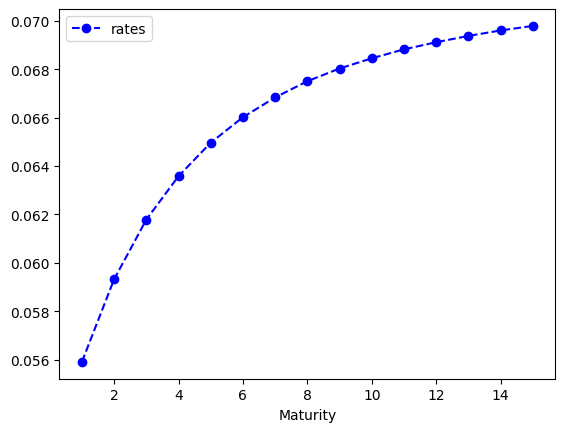

In [ ]:
etti_df.plot(marker='o', linestyle='--', color='b')

In [ ]:
def val_bono(coupon, maturity, discount):
    cash_flow = [coupon] * (maturity-1) + [100 + coupon]
    return cash_flow @ discount[:len(cash_flow)]


In [ ]:
coupon= 3 # cupón del 3 €
maturity= 5 # 5 años hasta vencimiento
discount= disc_factor # ETTI estimada
val_bono(coupon, maturity, discount)

np.float64(85.55493417443927)

## Cuando tenemos bonos con mismos vencimientos (Mininimos cuadrados ordinarios)
La realidad es más compleja y podemos tener bonos con el mismo vencimiento pero distintas rentabilidades. Por tanto estamos asumiendo que las condiciones del mercado no permiten que se cumpla la Ley del precio único. Podemos utilizar una aproximación por mínimos cuadrados (LS) para cada vencimiento, de modo que minimicemos el cuadrado de los errores de la valoración del conjunto de bonos.
$$d=(FC^T·FC)^{-1}·(FC^T·P)$$

In [ ]:
bonds_df_mult = pd.read_csv('Bonds_mult.csv', sep=';')
bonds_df_mult

,Bond,Price,Maturity,Coupon
0,A,91.897,1,2.0
1,B,83.256,2,2.5
2,C,76.000,3,3.0
3,D,76.235,3,3.2
4,E,71.211,4,3.5
5,F,67.967,5,4.0
6,G,66.000,6,4.5
7,H,66.163,6,4.2
8,I,65.488,7,5.0
9,J,65.700,8,5.5


In [ ]:
maturity_max_mult = bonds_df_mult['Maturity'].max()
maturity_max_mult

12

In [ ]:
# Generar flujos de caja
array_mult = []
for _, row in bonds_df_mult.iterrows():
    maturity = int(row['Maturity'])
    coupon = row['Coupon']
    flow = [coupon] * (maturity - 1) + [100 + coupon] + [0] * (maturity_max_mult - maturity)
    array_mult.append(flow)
array
# Crear DataFrame de flujos de caja
cash_flows_mult_df = pd.DataFrame(np.array(array_mult))
cash_flows_mult_df

,0,1,2,3,4,5,6,7,8,9,10,11
0,102.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2.5,102.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,3.0,3.0,103.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,3.2,3.2,103.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,3.5,3.5,3.5,103.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,4.0,4.0,4.0,4.0,104.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,4.5,4.5,4.5,4.5,4.5,104.5,0.0,0.0,0.0,0.0,0.0,0.0
7,4.2,4.2,4.2,4.2,4.2,104.2,0.0,0.0,0.0,0.0,0.0,0.0
8,5.0,5.0,5.0,5.0,5.0,5.0,105.0,0.0,0.0,0.0,0.0,0.0
9,5.5,5.5,5.5,5.5,5.5,5.5,5.5,105.5,0.0,0.0,0.0,0.0


In [ ]:
disc_factor_mult = np.linalg.inv(cash_flows_mult_df.T @ cash_flows_mult_df) @ cash_flows_mult_df.T @ bonds_df_mult['Price']
disc_factor_mult

,0
0,0.900943
1,0.790271
2,0.687433
3,0.607586
4,0.538668
5,0.486323
6,0.432697
7,0.391089
8,0.347329
9,0.323134


In [ ]:
bonds_df_mult['Price_calc'] = cash_flows_mult_df @ disc_factor_mult

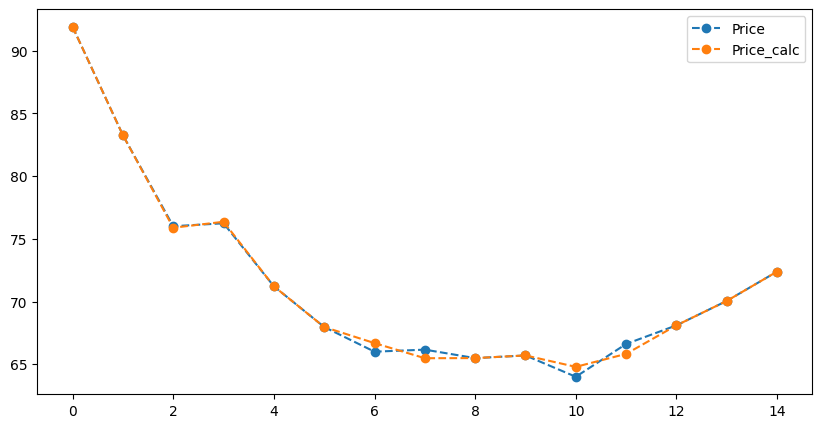

In [ ]:
bonds_df_mult[['Price', 'Price_calc']].plot(figsize=(10,5), marker='o', linestyle='--');

# Interpretación de las ETTI

Disponemos de tres aproximaciones teóricas diferentes para interpretar la información implicita en la ETTI:
- La teoría de las expectativas
- La teoría de la preferencia por la liquidez
- La hipótesis de la segmentación de mercados

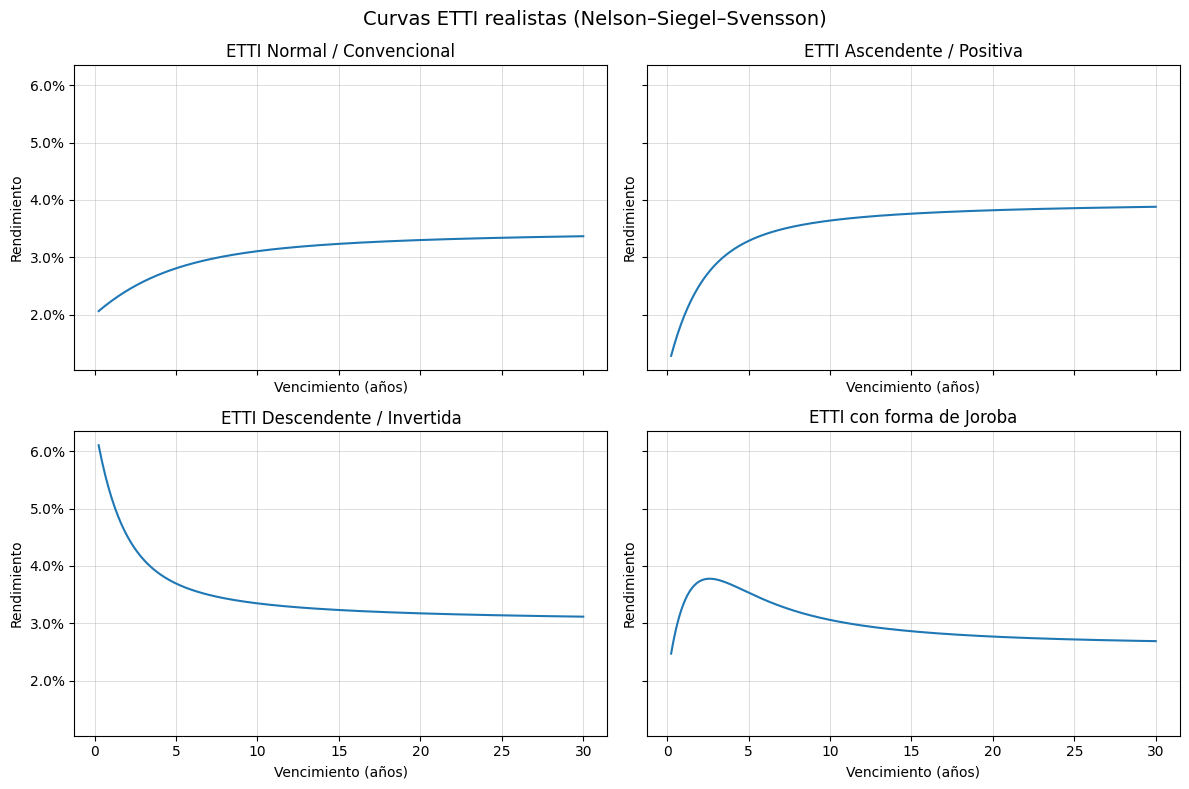

In [ ]:
def nss_yield(tau, beta0, beta1, beta2, beta3, lam1, lam2):
    """Nelson–Siegel–Svensson."""
    tau = np.asarray(tau, dtype=float)
    # Evitar división por cero en tau ~ 0
    x1 = (1 - np.exp(-tau/lam1)) / (tau/lam1)
    x2 = x1 - np.exp(-tau/lam1)
    x3 = (1 - np.exp(-tau/lam2)) / (tau/lam2) - np.exp(-tau/lam2)
    return beta0 + beta1 * x1 + beta2 * x2 + beta3 * x3

pct = FuncFormatter(lambda y, _: f"{100*y:.1f}%")

# Horizonte de vencimientos (años)
mats = np.linspace(0.25, 30, 300)

# ---------- Parámetros para cada forma ----------
# 1) Normal/Convencional: corto < largo, subida suave y nivel medio
y_normal = nss_yield(
    mats,
    beta0=0.035,  # nivel de largo plazo ~3.5%
    beta1=-0.015, # empuja el corto por debajo del largo
    beta2=-0.005, # ligera concavidad
    beta3=0.000,  # sin segunda joroba
    lam1=2.0, lam2=10.0
)

# 2) Ascendente/Positiva (más pronunciada): tipos muy bajos al corto, largos más altos
y_asc = nss_yield(
    mats,
    beta0=0.040,  # nivel de largo plazo ~4.0%
    beta1=-0.030, # corto muy por debajo (p.ej. ~1.0%)
    beta2=+0.006, # algo de curvatura
    beta3=0.000,
    lam1=1.5, lam2=8.0
)

# 3) Descendente/Invertida: corto alto y caída hacia un largo inferior
y_inv = nss_yield(
    mats,
    beta0=0.030,  # largo plazo bajo ~3.0%
    beta1=+0.035, # hace el corto alto (≈6.5%)
    beta2=-0.006, # ligera convexidad
    beta3=0.000,
    lam1=1.2, lam2=7.0
)

# 4) Con forma de joroba: pico en medianos y luego desciende
y_joroba = nss_yield(
    mats,
    beta0=0.026,   # nivel largo ~2.6%
    beta1=-0.006,  # arranque moderado
    beta2=+0.050,  # joroba principal en medianos
    beta3=-0.004,  # caída adicional en el muy largo
    lam1=1.3, lam2=9.0
)

# ---------- Gráficos 2×2 ----------
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)

# Arriba
axes[0,0].plot(mats, y_normal)
axes[0,0].set_title("ETTI Normal / Convencional")
axes[0,1].plot(mats, y_asc)
axes[0,1].set_title("ETTI Ascendente / Positiva")

# Abajo
axes[1,0].plot(mats, y_inv)
axes[1,0].set_title("ETTI Descendente / Invertida")
axes[1,1].plot(mats, y_joroba)
axes[1,1].set_title("ETTI con forma de Joroba")

# Ejes y formato
for ax in axes.ravel():
    ax.grid(True, lw=0.5, alpha=0.6)
    ax.yaxis.set_major_formatter(pct)
    ax.set_xlabel("Vencimiento (años)")
    ax.set_ylabel("Rendimiento")

fig.suptitle("Curvas ETTI realistas (Nelson–Siegel–Svensson)", fontsize=14, y=0.98)
plt.tight_layout()
plt.show()

## La teoría de las expectativas

La teoría de las expectativas sostiene que la curva de rendimientos refleja las expectativas de los inversores acerca de la evolución futura de los tipos de interés, atribuyéndole así un carácter predictivo.

Dentro de este marco se encuentra la hipótesis de las expectativas locales, la cual plantea que todos los bonos de una misma categoría, independientemente de su plazo de vencimiento, deberían ofrecer la misma rentabilidad esperada. Bajo esta premisa, un bono a seis meses y un bono a veinte años deberían proporcionar el mismo rendimiento.

No obstante, el riesgo de reinversión introduce una diferencia fundamental: los bonos con plazos largos suelen ofrecer rendimientos superiores a los de corto plazo, dado que la reinversión de los cupones intermedios puede realizarse a tipos de interés futuros inciertos. Sin embargo, si un inversor adquiere un bono cupón cero a veinte años, elimina dicho riesgo de reinversión, por lo que debería obtener el mismo rendimiento que una estrategia consistente en renovar bonos a corto plazo sin riesgo de impago. En la práctica, los rendimientos a largo plazo suelen superar a los rendimientos anualizados de corto plazo.

Rubinstein (1999) subraya que los tipos de interés futuros al contado no son conocidos con certeza, lo que otorga ventajas a los bonos de corto plazo:
1. Son instrumentos más adecuados para fines de cobertura.
2. Presentan mayor liquidez, al poder convertirse en efectivo con mayor facilidad que los instrumentos a largo plazo.

Estas razones explican por qué en la práctica se observa con frecuencia la ETTI de forma normal o convencional, caracterizada por una pendiente positiva moderada.

Por otro lado, la hipótesis de expectativas puras plantea que los tipos de interés a plazo implícitos en la curva actual son estimadores insesgados de los tipos de interés al contado futuros:

$$(1+S(n))^n = (1+S(n-1)) \cdot (1+F(n-1,n))$$

No obstante, esta hipótesis —también denominada de expectativas imparciales— no basta por sí sola para explicar todas las formas posibles de la curva de rendimientos ni la información que contiene. Por ello, suele combinarse con otros enfoques, como la teoría de la preferencia por la liquidez, que introduce un sesgo positivo en los rendimientos de mayor plazo debido a la prima de liquidez exigida por los inversores.

## La teoría de la preferencia por la liquidez

Como ya hemos señalado anteriormente un mayor periodo de vencimiento lleva implícito siempre un mayor riesgo.

Supongamos que las expectativas de inflación se van a mantener estables durante una poeriodo largo de tiempo. En este contexto, el mercado anticipa una curva de rendimiento positiva.La hipótesis de las expectativas no puede explicar por sí sola este fenómeno, ya que en condiciones de inflación estable cabría esperar una curva de rendimiento plana. Dado que inversioes con mayor periodo de vencimiento lleva implícito siempre un mayor riesgo, los inversores sólo estarán dispuesto a realizar este tipo de inversiones a camabio de una prima por liquidez que compense el incremento de riesgo por la pérdida de liquidez. Las primas tendrían la siguiente estructura:

$$0=L_1<L_2<...<L_n$$

La hipótesis de las espectativas propone que el tipos de interés forward es un estimador insesgado del tipo de interés spot futuro:
$$F(n_1,n)=E(S(n-1,n))$$

La hipótesisi de la hipótesis de la preferencia por la liquidez indica
$$F(n_1,n)=E(S(n-1,n))+L_n$$
![image.png](attachment:acbc55a2-18ee-4485-9518-4bbd70acecbc.png)![image.png](attachment:46bcd1be-9e9e-4cfb-9800-0cc996ecbfe6.png)

## La hipótesis de la segmentación de mercados

La teoría de los mercados segmentados sugiere que la actividad se concentra en determinadas áreas específicas del mercado y que no existen interrelaciones entre estas partes del mercado. Las cantidades relativas de fondos invertidos en cada uno de los espectros de vencimiento provocan diferencias en la oferta y la demanda, lo que da lugar a protuberancias en la curva de rendimiento. Es decir, la forma de la curva de rendimiento viene determinada por la oferta y la demanda de determinadas inversiones con vencimientos específicos, cada una de las cuales no tiene referencia alguna con respecto a cualquier otra parte de la curva.